# Climate Change in Friuli Venezia Giulia: 35 Years of Weather Data

Has the climate in Friuli Venezia Giulia measurably changed over the last 35 years? This notebook examines temperature, rainfall, humidity and extreme 
weather patterns across a network of stations spanning the region - from the Adriatic coast to the Julian Alps - using daily observations from the OSMER archive since 1991.

**Data source:** [ARPA FVG - OSMER e GRN](http://www.meteo.fvg.it/), licensed under CC BY-SA 3.0 IT.


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Plotting style (matches house style across the portfolio)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Paths
DATA_DIR = Path('..') / 'data'
RAW_DIR = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
PROCESSED_DIR.mkdir(exist_ok=True)

# Numeric measurement columns, used throughout
NUMERIC_COLS = [
    'rain_mm', 'temp_min', 'temp_mean', 'temp_max',
    'humidity_min', 'humidity_mean', 'humidity_max',
    'wind_mean', 'wind_max', 'wind_dir_max',
    'radiation_kj_m2', 'pressure_hpa',
]

## Part 1 — Data Preparation

The pipeline:
1. Load all per-station-year CSVs scraped from OSMER
2. Clean column names, parse dates, convert dashes to NaN
3. Merge "old/new" station pairs that share a physical location
4. Resolve overlap days (same station, same date in both old & new records)
5. Drop empty rows (dates present but no observations recorded)
6. Filter to high-quality stations and the analysis time window
7. Save the processed dataset

The resulting `climate_daily.csv` is what all downstream analysis uses.

### 1.1 Load raw CSVs and station metadata

In [58]:
def load_all_raw(raw_dir: Path) -> pd.DataFrame:
    """Load every per-(station, year) CSV in raw/ into one DataFrame."""
    dfs = []
    for path in sorted(raw_dir.glob('*.csv')):
        name = path.stem  # e.g. "Udine_2020"
        station_key, year = name.rsplit('_', 1)
        df = pd.read_csv(path)
        df['station_key'] = station_key
        df['year'] = int(year)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

raw = load_all_raw(RAW_DIR)
stations = pd.read_csv(DATA_DIR / 'stations.csv')

print(f"Raw rows: {len(raw):,}")
print(f"Stations in metadata: {len(stations)}")
print(f"Stations found in data: {raw['station_key'].nunique()}")
print(f"Year range: {raw['year'].min()} – {raw['year'].max()}")

Raw rows: 812,543
Stations in metadata: 63
Stations found in data: 63
Year range: 1991 – 2026


### 1.2 Clean column names, parse dates, convert dashes to NaN

The OSMER HTML uses Italian column names with embedded units (e.g. `Pioggia mm`, `Temp. med °C`). We rename them to short English identifiers for easier use, replace the `-` placeholder with proper NaN, and build a single `date` column from year/month/day.

In [71]:
COL_RENAME = {
    'mese':              'month',
    'giorno*':            'day',
    'Pioggia mm':        'rain_mm',
    'Temp. min °C':      'temp_min',
    'Temp. med °C':      'temp_mean',
    'Temp. max °C':      'temp_max',
    'Umidità min %':     'humidity_min',
    'Umidità med %':     'humidity_mean',
    'Umidità max %':     'humidity_max',
    'Vento med km/h':    'wind_mean',
    'Vento max km/h':    'wind_max',
    'Dir. V. max °N':    'wind_dir_max',
    'Radiaz. KJ/m2':     'radiation_kj_m2',
    'Press. med hPa':    'pressure_hpa',
}

raw = raw.rename(columns={k: v for k, v in COL_RENAME.items() if k in raw.columns})
raw = raw.replace('-', np.nan)

for col in [c for c in NUMERIC_COLS if c in raw.columns]:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

raw['date'] = pd.to_datetime(raw[['year', 'month', 'day']], errors='coerce')
raw = raw.dropna(subset=['date'])

print(f"After cleaning: {len(raw):,} rows")

After cleaning: 812,507 rows


### 1.3 Merge old/new station pairs

OSMER sometimes has two entries for the same physical station — typically an "old" entry that stopped reporting on some date, and a "new" entry that took over. These pairs share identical coordinates. We merge them into single canonical records to preserve continuity. 

(Stations where equipment moved to a different location are kept separate, since microclimate may genuinely differ.)

In [92]:
# Old/new station pairs that share identical coordinates (verified from stations.csv)
MERGE_MAP = {
    'MuggiaPluvio':      'Muggia',
    'Lignano_old':       'LignanoSabbiadoro',
    'Monfalcone_old':    'Monfalcone',
    'MonfalconePluvio':  'Monfalcone',
    'Ariis_old':         'Ariis',
    'Pordenone_old':     'PordenoneMeteo',
    'Barcis_old':        'Barcis',
    'Pontebba_old':      'Pontebba',
    'MonteLussari_old':  'MonteLussari',   # ← slight physical offset, same mountain
}


processed = raw.copy()
processed['station_key'] = processed['station_key'].replace(MERGE_MAP)

print(f"Stations before merge: {raw['station_key'].nunique()}")
print(f"Stations after merge:  {processed['station_key'].nunique()}")

Stations before merge: 62
Stations after merge:  53


### 1.4 Resolve overlap days

After the merge, some (station, date) combinations appear twice - once from the old installation and once from the new. When both exist, we keep the row with more non-NaN measurements as the more informative one.

In [93]:
# For each duplicate (station, date), keep the row with the most observations
processed['n_obs'] = processed[NUMERIC_COLS].notna().sum(axis=1)
processed = (
    processed
    .sort_values(['station_key', 'date', 'n_obs'], ascending=[True, True, False])
    .drop_duplicates(subset=['station_key', 'date'], keep='first')
    .drop(columns=['n_obs'])
    .reset_index(drop=True)
)

print(f"After dedup: {len(processed):,} rows")

After dedup: 694,562 rows


### 1.5 Drop empty rows

Some (station, date) combinations exist but have no measurements at all (every numeric column is NaN). These are usually "day exists in the archive page but no sensor was reporting." We drop them.

In [94]:
before = len(processed)
processed = processed.dropna(subset=NUMERIC_COLS, how='all').reset_index(drop=True)
after = len(processed)

print(f"Dropped {before - after:,} all-NaN rows ({100*(before-after)/before:.1f}%)")
print(f"Remaining: {after:,} rows")

Dropped 221,397 all-NaN rows (31.9%)
Remaining: 473,165 rows


### 1.6 Data coverage inspection

Before selecting stations for analysis, we visualise the coverage of temperature observations per (station, year) to understand which stations have continuous long-term records.

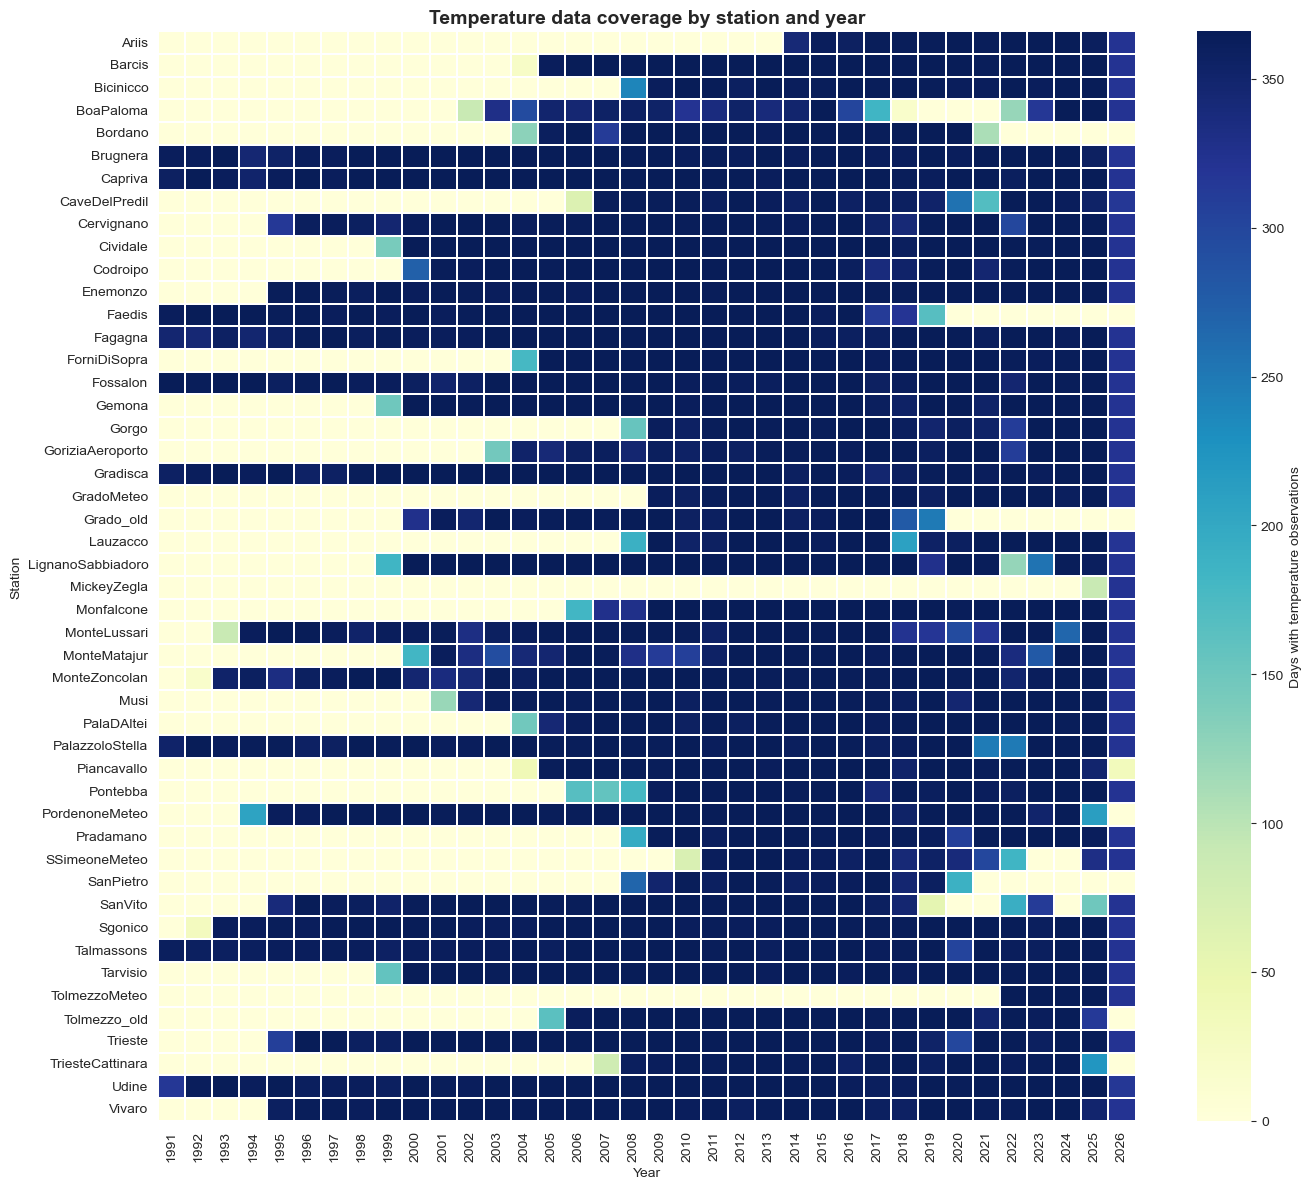

In [95]:
coverage = (
    processed[processed['temp_mean'].notna()]
    .groupby(['station_key', 'year']).size().reset_index(name='days')
    .pivot(index='station_key', columns='year', values='days')
    .fillna(0).astype(int)
)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    coverage, cmap='YlGnBu',
    cbar_kws={'label': 'Days with temperature observations'},
    linewidths=0.3, linecolor='white', ax=ax
)
ax.set_title('Temperature data coverage by station and year', fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Station')
plt.tight_layout()
plt.show()

### 1.7 Select stations and time window

From the coverage heatmap, we pick 14 stations that have continuous records 
over most of 1993–2024 and that together span the region's full elevation 
gradient (0 m → 1750 m) and east–west extent.

**Time window:** 1993–2024 (32 years). Before 1993 only a handful of stations 
were reporting; after 2024 the recent-data validation is incomplete.

In [70]:
SELECTED_STATIONS = [
    # Coast / coastal plain
        'Fossalon',         # 0 m
        'PalazzoloStella',  # 5 m
    'Trieste',          # 1 m — Bora exposure
    # Plains
        'Udine',            # 91 m — central
    'SanVito',          # 21 m
        'Brugnera',         # 22 m
        'Talmassons',       # 16 m
        'Gradisca',         # 29 m
        'Capriva',          # 85 m — Collio
    # Foothills
        'Fagagna',          # 148 m
    'Vivaro',           # 142 m
    'Enemonzo',         # 438 m — Carnia
    # Alps
    'Tarvisio',          # 794 m — valley
    'MonteZoncolan',     # 1750 m — Carnian Alps (west)
    'MonteLussari',      # 1743 m — Julian Alps (east)
]

df = processed[
    (processed['station_key'].isin(SELECTED_STATIONS)) &
    (processed['year'].between(1993, 2024))
].copy()

# Save the processed dataset
out_path = PROCESSED_DIR / 'climate_daily.csv'
df.to_csv(out_path, index=False)

print(f"Selected: {len(df):,} rows, {df['station_key'].nunique()} stations")
print(f"Year range: {df['year'].min()} – {df['year'].max()}")
print(f"Saved: {out_path}")

Selected: 159,711 rows, 14 stations
Year range: 1993 – 2024
Saved: ..\data\processed\climate_daily.csv


---

**End of Part 1.** The processed dataset `data/processed/climate_daily.csv` is now the single source of truth for the analysis that follows. In future 
sessions, we can skip Part 1 and load directly:

```python
df = pd.read_csv('../data/processed/climate_daily.csv', parse_dates=['date'])
```

---

## Part 2 — Analysis

*(coming in next session)*

Planned sections:
- 2.1 Temperature trends — annual mean, warming per decade
- 2.2 Extreme heat — hot days per year, max daily temperature
- 2.3 Extreme cold — frost days, cold snaps  
- 2.4 Rainfall patterns — totals, intensity, dry/wet spells
- 2.5 Elevation gradient — does warming vary with altitude?
- 2.6 Conclusion